# 09 Excel 写入与工作簿编排

每节下方的完整代码块均可单独复制运行，包含自己的 import、数据加载和实际调用。使用全部订单，不做行采样。安装所需依赖后，从 `examples` 目录运行。

In [ ]:
import sys
sys.path.append('../')

## 1. 快速写入与表格格式

从全量订单生成客群汇总，展示百分比、金额、条件格式和自动列宽。汇总不是行采样。

In [1]:
import sys

sys.path.append("../")

import numpy as np
import pandas as pd
from IPython.display import display
from hscredit import hscredit_dataset
from hscredit.utils.datasets import HSCREDIT_EXAMPLE_COLUMNS
from pathlib import Path
from tempfile import mkdtemp
from hscredit.excel import ExcelWriter, dataframe2excel

data = hscredit_dataset(columns=HSCREDIT_EXAMPLE_COLUMNS)

data["授信月份"] = pd.to_datetime(data["授信时间"]).dt.to_period("M").astype(str)
data["坏样本"] = data["MOB6"].gt(30).astype(int)
detail = data[
    ["GROUP", "BASE_X61", "BASINF_X19", "授信月份", "loan_amt", "periods", "坏样本"]
].rename(
    columns={
        "GROUP": "客群",
        "BASE_X61": "行业",
        "BASINF_X19": "学位",
        "loan_amt": "审批额度",
        "periods": "合同期数",
    }
)

summary = (
    detail.groupby("客群", observed=True)
    .agg(订单数=("坏样本", "size"), 审批额度=("审批额度", "sum"), 坏样本率=("坏样本", "mean"))
    .reset_index()
)
display(summary)
output = Path(mkdtemp(prefix="hscredit_excel_quick_"))
dataframe2excel(
    summary,
    output / "客群汇总.xlsx",
    sheet_name="客群汇总",
    percent_cols=["坏样本率"],
    condition_cols=["审批额度"],
    auto_width=True,
    index=False,
)
print(output)

,客群,订单数,审批额度,坏样本率
0,优质客群-公积金类,1796,12855000.0000,0.0618
1,优质客群-房贷类,10597,76732000.0000,0.0760
2,优质客群-消费金融类,17648,127957000.0000,0.0794
3,衍生客群,76392,493999008.0000,0.0954
4,高危客群,5496,35486000.0000,0.0964


C:\Users\18306\AppData\Local\Temp\hscredit_excel_quick_nns8fhig


## 2. 标题、明细、冻结、筛选与超链接

全量订单明细写入同一工作簿，汇总页与明细页互相链接。

In [1]:
import sys

sys.path.append("../")

import numpy as np
import pandas as pd
from IPython.display import display
from hscredit import hscredit_dataset
from hscredit.utils.datasets import HSCREDIT_EXAMPLE_COLUMNS
from pathlib import Path
from tempfile import mkdtemp
from hscredit.excel import ExcelWriter, dataframe2excel

data = hscredit_dataset(columns=HSCREDIT_EXAMPLE_COLUMNS)

data["授信月份"] = pd.to_datetime(data["授信时间"]).dt.to_period("M").astype(str)
data["坏样本"] = data["MOB6"].gt(30).astype(int)
detail = data[
    ["GROUP", "BASE_X61", "BASINF_X19", "授信月份", "loan_amt", "periods", "坏样本"]
].rename(
    columns={
        "GROUP": "客群",
        "BASE_X61": "行业",
        "BASINF_X19": "学位",
        "loan_amt": "审批额度",
        "periods": "合同期数",
    }
)

output = Path(mkdtemp(prefix="hscredit_excel_detail_"))
writer = ExcelWriter(theme_color="2639E9", condition_color="F76E6C")
sheet = writer.get_sheet_by_name("订单明细")
writer.insert_value2sheet(sheet, "A1", value="现金贷订单明细", style="header", end_space="G1")
writer.insert_df2sheet(sheet, detail, "A3", header=True, index=False, auto_width=True)
writer.set_freeze_panes(sheet, "A4")
writer.add_auto_filter(sheet, f"A3:G{len(detail) + 3}")
writer.set_number_format(sheet, f"E4:E{len(detail) + 3}", "#,##0.00")
writer.add_conditional_formatting(sheet, "E4", f"E{len(detail) + 3}")
writer.set_row_height(sheet, 1, 26)
writer.insert_hyperlink2sheet(sheet, "I1", sheet="客群汇总", target_space="B2")
summary = detail.groupby("客群", observed=True)["审批额度"].agg(["count", "sum", "mean"])
dataframe2excel(summary, writer, sheet_name="客群汇总", index=True, auto_width=True)
writer.save(output / "订单明细与汇总.xlsx")
print(output)

C:\Users\18306\AppData\Local\Temp\hscredit_excel_detail_jjjvzoyp


## 3. 多级表头、图片与 DataFrame.show

先生成真实统计图，再将图与多级表头放入同一 Excel。

客群,订单数,坏样本率
优质客群-公积金类,1796,6.18%
优质客群-房贷类,10597,7.60%
优质客群-消费金融类,17648,7.94%
衍生客群,76392,9.54%
高危客群,5496,9.64%


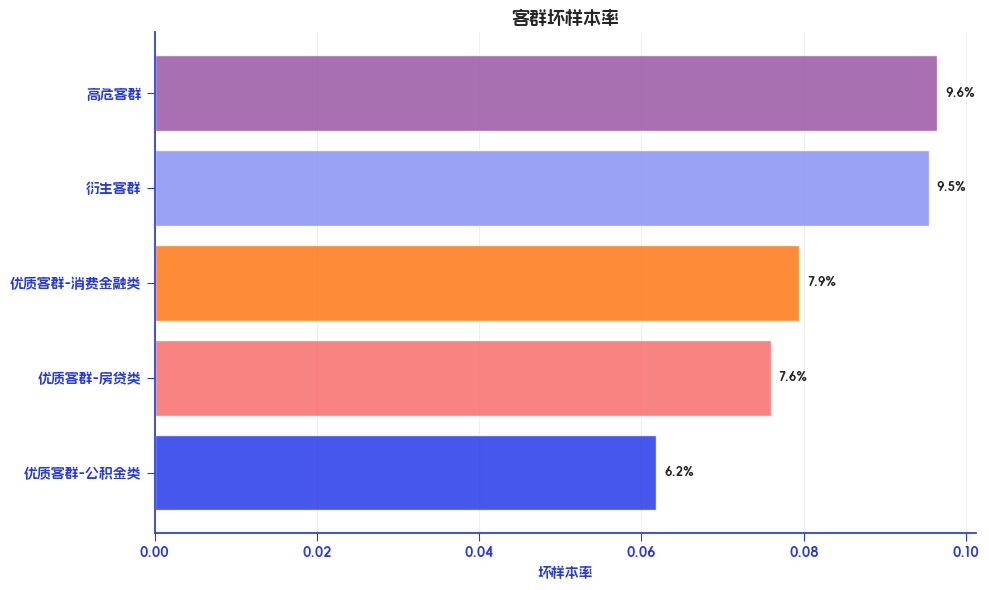

C:\Users\18306\AppData\Local\Temp\hscredit_excel_plots_sc70dypz


In [1]:
import sys

sys.path.append("../")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from hscredit import hscredit_dataset
from hscredit.utils.datasets import HSCREDIT_EXAMPLE_COLUMNS
from pathlib import Path
from tempfile import mkdtemp
from hscredit.excel import ExcelWriter, dataframe2excel

from hscredit import init_setting
from hscredit.core.viz import metric_comparison_plot

data = hscredit_dataset(columns=HSCREDIT_EXAMPLE_COLUMNS)

data["授信月份"] = pd.to_datetime(data["授信时间"]).dt.to_period("M").astype(str)
data["坏样本"] = data["MOB6"].gt(30).astype(int)
detail = data[
    ["GROUP", "BASE_X61", "BASINF_X19", "授信月份", "loan_amt", "periods", "坏样本"]
].rename(
    columns={
        "GROUP": "客群",
        "BASE_X61": "行业",
        "BASINF_X19": "学位",
        "loan_amt": "审批额度",
        "periods": "合同期数",
    }
)

init_setting()
output = Path(mkdtemp(prefix="hscredit_excel_plots_"))
summary = (
    detail.groupby("客群", observed=True)
    .agg(订单数=("坏样本", "size"), 坏样本率=("坏样本", "mean"))
    .reset_index()
)
display(summary.show())
figure = metric_comparison_plot(
    summary, label_col="客群", value_col="坏样本率", title="客群坏样本率", value_format="{:.1%}"
)
display(figure)
figure.savefig(output / "客群坏样本率.png", bbox_inches="tight")

writer = ExcelWriter()
dataframe2excel(summary, writer, sheet_name="客群分析", percent_cols=["坏样本率"], index=False)
writer.insert_pic2sheet(
    writer.get_sheet_by_name("客群分析"), str(output / "客群坏样本率.png"), "B12"
)
hierarchical = detail.groupby(["客群", "授信月份"], observed=True).agg(
    {"审批额度": ["sum", "mean"], "坏样本": ["size", "mean"]}
)
dataframe2excel(hierarchical, writer, sheet_name="多级表头", index=True, auto_width=True)
writer.save(output / "多表多图.xlsx")
print(output)

plt.close("all")

## 4. 原生透视表、读取已有文件与追加

本节先创建自己的源工作簿，再读取、追加、另存；无需执行其他章节，也不覆盖已有报告。

In [1]:
import sys

sys.path.append("../")

import numpy as np
import pandas as pd
from IPython.display import display
from hscredit import hscredit_dataset
from hscredit.utils.datasets import HSCREDIT_EXAMPLE_COLUMNS
from pathlib import Path
from tempfile import mkdtemp
from hscredit.excel import ExcelWriter, dataframe2excel

data = hscredit_dataset(columns=HSCREDIT_EXAMPLE_COLUMNS)

data["授信月份"] = pd.to_datetime(data["授信时间"]).dt.to_period("M").astype(str)
data["坏样本"] = data["MOB6"].gt(30).astype(int)
detail = data[
    ["GROUP", "BASE_X61", "BASINF_X19", "授信月份", "loan_amt", "periods", "坏样本"]
].rename(
    columns={
        "GROUP": "客群",
        "BASE_X61": "行业",
        "BASINF_X19": "学位",
        "loan_amt": "审批额度",
        "periods": "合同期数",
    }
)

output = Path(mkdtemp(prefix="hscredit_excel_pivot_"))
writer = ExcelWriter()
source = writer.get_sheet_by_name("订单明细")
writer.insert_df2sheet(source, detail, "A1", header=True, index=False, auto_width=True)
writer.insert_pivot_table2sheet(
    worksheet="原生透视表",
    pivot_anchor="B2",
    source_sheet=source,
    source_range=f"A1:G{len(detail) + 1}",
    rows="客群",
    columns="授信月份",
    filters="学位",
    values=[
        {"field": "审批额度", "agg": "sum", "name": "额度合计", "number_format": "#,##0"},
        {"field": "坏样本", "agg": "average", "name": "坏样本率", "number_format": "0.00%"},
    ],
    name="订单透视表",
)
writer.save(output / "原始工作簿.xlsx")

existing = ExcelWriter(style_excel=str(output / "原始工作簿.xlsx"), mode="append")
industry_summary = detail.groupby("行业", observed=True)["审批额度"].agg(["count", "sum", "mean"])
dataframe2excel(industry_summary, existing, sheet_name="新增行业汇总", index=True, auto_width=True)
existing.save(output / "追加后的工作簿.xlsx")
print(output)

C:\Users\18306\AppData\Local\Temp\hscredit_excel_pivot_8848k4fc
